In [ ]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import seaborn as sns

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "src"))
sys.path.insert(0, src_dir)

#import the module
import corr_utils

from joblib import dump, load
from scipy.cluster.hierarchy import fcluster
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram
from sklearn.utils import resample
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

from sklearn.decomposition import PCA

import networkx as nx

## PROTEIN - PROTEIN CORRELATION CLUSTERING

In [ ]:
proteins = load('data/full_prot.joblib')
proteins

,A2M,AAAS,AACS,AAGAB,AAK1,AAMDC,AAMP,AAR2,AARS,AARS2,...,ZNF787,ZNF800,ZNF830,ZNHIT6,ZNRD1,ZRANB2,ZW10,ZWILCH,ZYX,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,1.000000,0.000000,0.000000,0.000000,0.225561,0.000000,0.121652,0.143729,0.000000,0.000000,...,-0.170119,0.000000,-0.192738,0.000000,0.000000,-0.146868,0.000000,0.000000,0.114483,0.000000
AAAS,0.000000,1.000000,-0.233390,-0.345984,0.000000,-0.388692,-0.281584,0.216806,-0.294110,0.334116,...,-0.153136,0.167936,0.000000,0.181163,0.000000,0.000000,0.293679,0.000000,-0.186656,0.000000
AACS,0.000000,-0.218348,1.000000,0.321220,0.242881,0.245037,0.273681,0.196180,0.425103,0.000000,...,-0.112829,0.000000,-0.284120,-0.198949,-0.413636,-0.228468,0.312351,0.478636,0.136107,-0.403005
AAGAB,0.000000,-0.340601,0.326584,1.000000,0.160591,0.333963,0.490817,0.122178,0.477098,-0.249742,...,0.000000,-0.205432,0.000000,0.000000,0.000000,0.000000,0.000000,0.433279,0.207931,-0.133559
AAK1,0.224240,-0.128369,0.241084,0.154089,1.000000,0.169175,0.302847,0.236585,0.293882,0.000000,...,-0.183840,0.000000,-0.339322,-0.181509,-0.299583,-0.200646,0.191614,0.267412,0.427129,-0.312405
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,-0.149387,0.000000,-0.228664,0.000000,-0.197585,0.180600,0.000000,-0.173096,0.000000,0.000000,...,0.297751,0.000000,0.424778,0.178508,0.421273,1.000000,-0.290277,-0.118772,0.000000,0.448726
ZW10,0.000000,0.301440,0.301829,0.000000,0.170618,0.000000,0.000000,0.380405,0.162413,0.183555,...,-0.212251,0.152209,-0.375406,0.000000,-0.370570,-0.299930,1.000000,0.450707,0.000000,-0.442071
ZWILCH,0.000000,0.000000,0.486649,0.444735,0.268711,0.301823,0.438029,0.368233,0.541679,-0.113909,...,0.000000,0.000000,-0.205280,0.000000,-0.273549,-0.118606,0.453857,1.000000,0.243504,-0.344517


Clustermap

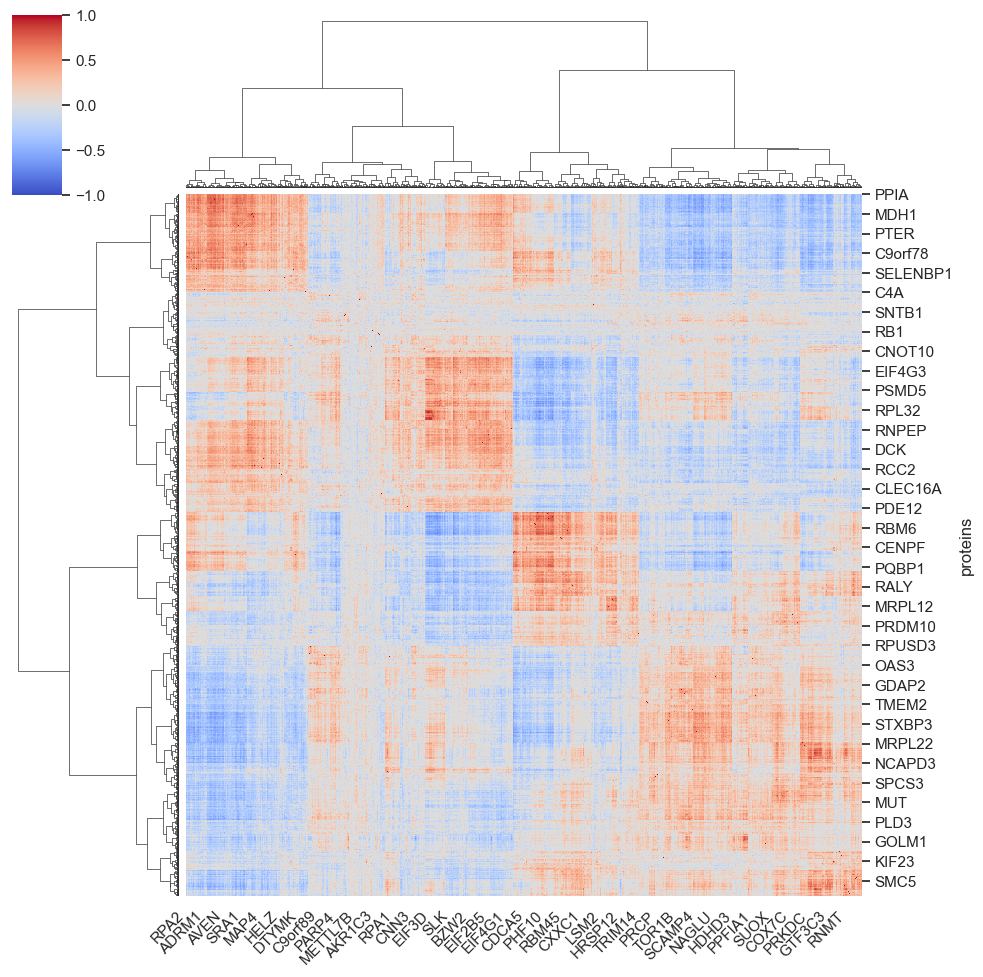

In [ ]:
os.makedirs('results/clustermaps', exist_ok=True)

# Create the clustermap.
sns.set_theme(style="white")
g = sns.clustermap(
    proteins,
    method="ward",         # Clustering method
    metric="euclidean",    # Distance metric
    cmap="coolwarm",           # Color map for correlation data
    center=0,              # Center the colormap at zero
    vmin=-1, vmax=1,       # Expected correlation range
    #standard_scale=1,      # Standardize each row (protein)
    figsize=(10, 10)       # Figure size
)

# 5. Rotate x-axis labels for readability.
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
g.savefig('results/clustermaps/map_pp_raw.png', dpi=300, bbox_inches='tight')

plt.show()

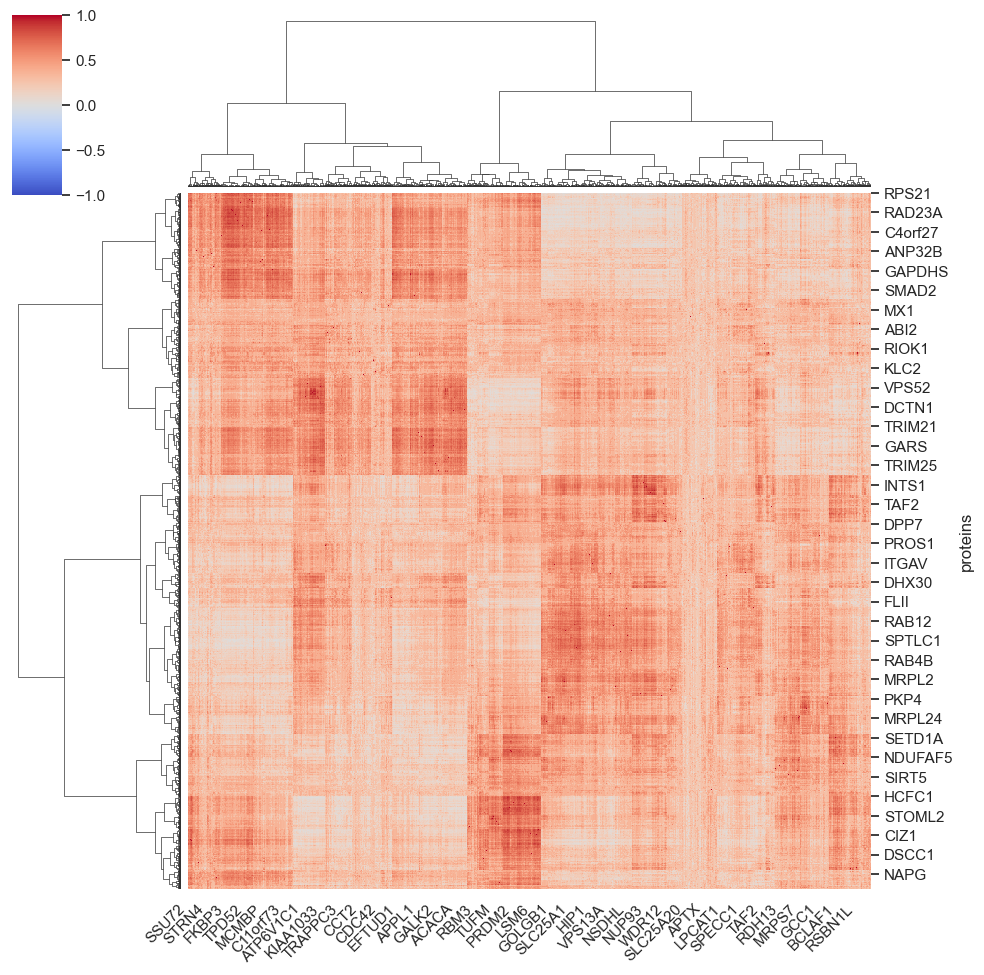

In [ ]:
# Create the clustermap.
sns.set_theme(style="white")
g = sns.clustermap(
    proteins,
    method="ward",         # Clustering method
    metric="euclidean",    # Distance metric
    cmap="coolwarm",           # Color map for correlation data
    center=0,              # Center the colormap at zero
    vmin=-1, vmax=1,       # Expected correlation range
    standard_scale=1,      # Standardize each row (protein)
    figsize=(10, 10)       # Figure size
)

# 5. Rotate x-axis labels for readability.
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
g.savefig('results/clustermaps/map_pp_std.png', dpi=300, bbox_inches='tight')

plt.show()

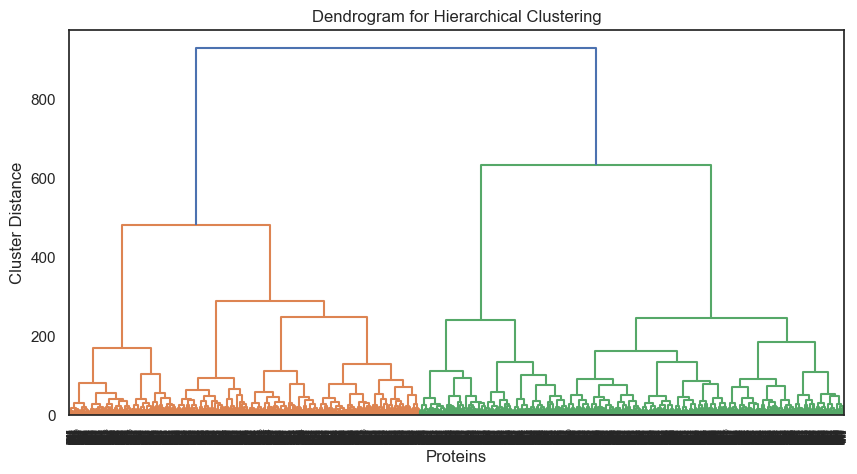

In [ ]:
#row_linkage1 = g.dendrogram_row.linkage
row_linkage1 = sch.linkage(proteins, method="ward", metric="euclidean")
corr_utils.plot_dendrogram(row_linkage1)

#### Save clusters

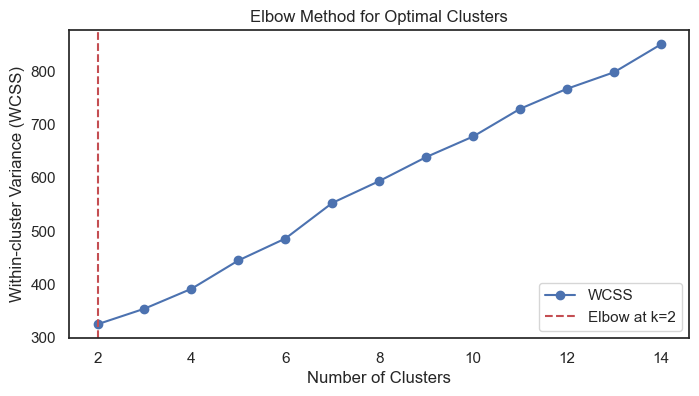

Saved cluster assignments for k=2 to 'results/clusters_pp/prot_prot_clusters_k2.csv'
Saved cluster assignments for k=3 to 'results/clusters_pp/prot_prot_clusters_k3.csv'
Saved cluster assignments for k=4 to 'results/clusters_pp/prot_prot_clusters_k4.csv'
Saved cluster assignments for k=5 to 'results/clusters_pp/prot_prot_clusters_k5.csv'
Saved cluster assignments for k=6 to 'results/clusters_pp/prot_prot_clusters_k6.csv'
Saved cluster assignments for k=7 to 'results/clusters_pp/prot_prot_clusters_k7.csv'

All cluster assignments from k=2 to k=2 have been saved to the 'results/clusters_pp' folder.


In [ ]:
# 2. Elbow Method
elbow_k = corr_utils.elbow_method(proteins, row_linkage1)

# 3. Silhouette Score Method
silhouette_k = corr_utils.silhouette_method(proteins, row_linkage1)

# Create the directory if it doesn't exist
os.makedirs("results/clusters_pp", exist_ok=True)

# Save cluster assignments for all values from 2 to silhouette_k
for k in range(2, 8):
    # Get cluster labels for this k
    cluster_labels = fcluster(row_linkage1, k, criterion='maxclust')
    
    # Create a DataFrame mapping each protein to its cluster
    clusters_df = pd.DataFrame({
        'Protein': proteins.index,
        'Cluster': cluster_labels
    })
    
    # Define the output file path
    output_file = f"results/clusters_pp/prot_prot_clusters_k{k}.csv"
    
    # Save the cluster assignments to a CSV file
    clusters_df.to_csv(output_file, index=False)
    
    print(f"Saved cluster assignments for k={k} to '{output_file}'")

print(f"\nAll cluster assignments from k=2 to k={silhouette_k} have been saved to the 'results/clusters_pp' folder.")

In [ ]:
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")


Network Density: 0.1233200100269129
Network Modularity: 0.6189786102589288

Top 5 Hub Proteins (by Degree Centrality):
CCDC47: 0.2502
FAF2: 0.2433
MRPL37: 0.2432
MTG1: 0.2412
MFN1: 0.2408


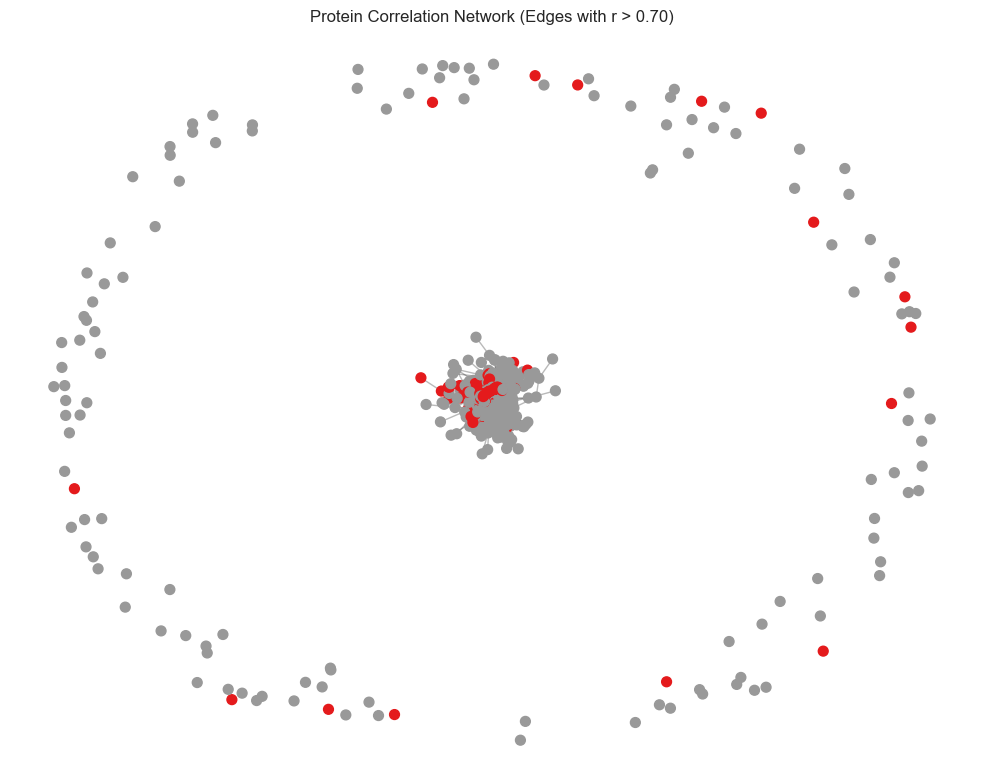

In [ ]:
# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = proteins.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes 
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(proteins.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()

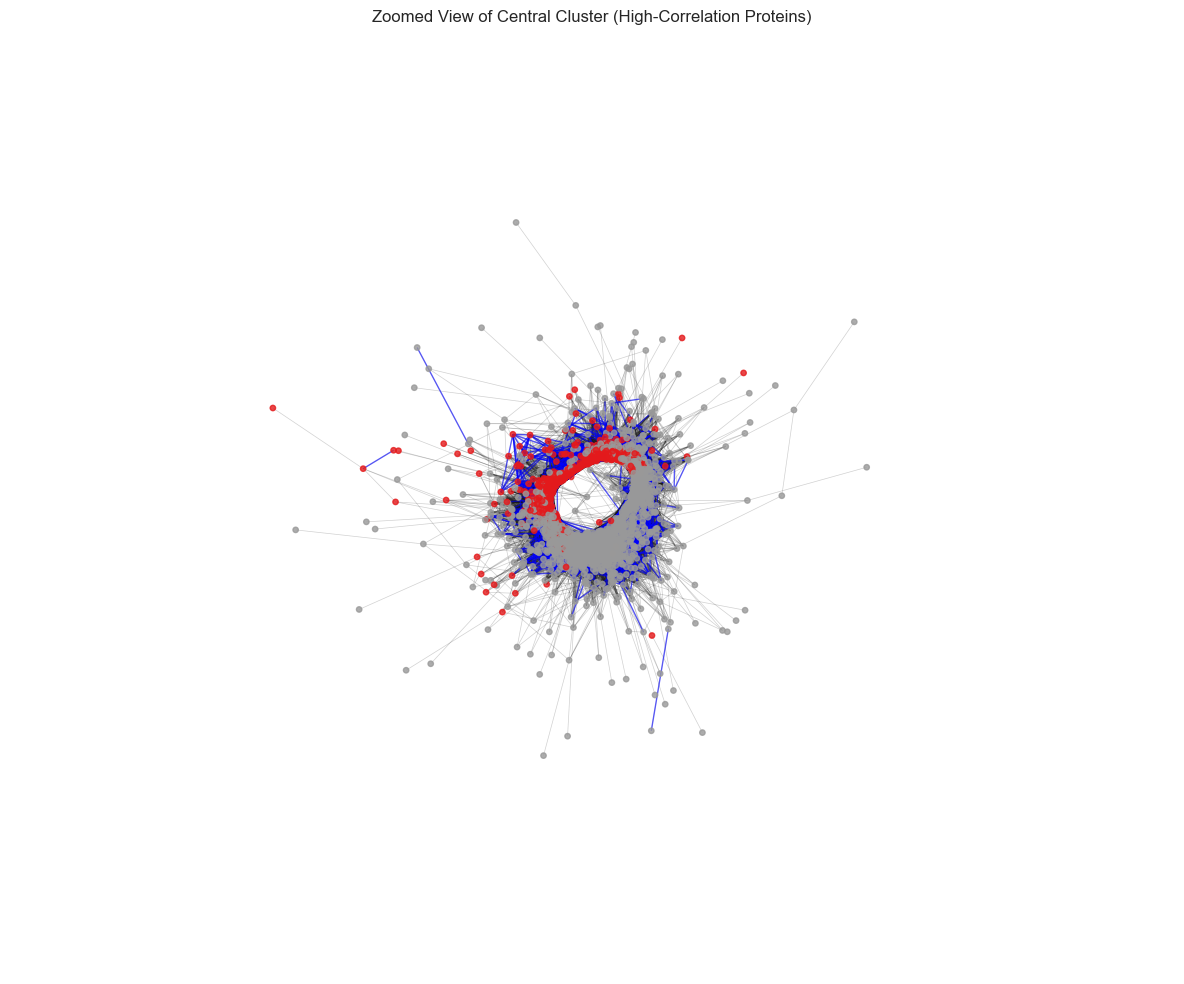

In [ ]:
# Create zoomed version of central cluster
plt.figure(figsize=(12, 10))

# Get the same layout as the original visualization for consistency
pos = nx.spring_layout(G, seed=42)  # Use same seed as original for consistency

# Get the approximate center coordinates
x_coords = [coord[0] for coord in pos.values()]
y_coords = [coord[1] for coord in pos.values()]
center_x = sum(x_coords) / len(x_coords)
center_y = sum(y_coords) / len(y_coords)

# Define radius for central region
radius = 0.3  # Adjust this value to control zoom level

# Identify nodes in the central region
central_nodes = [node for node in G.nodes() if 
                ((pos[node][0] - center_x)**2 + (pos[node][1] - center_y)**2) < radius**2]

# Draw edges with increased transparency for better visibility
central_edge_list = [(u, v) for u, v in G.edges() if u in central_nodes and v in central_nodes]
central_G = nx.Graph()
central_G.add_edges_from(central_edge_list)
nx.draw_networkx_edges(central_G, pos, alpha=0.2, width=0.5)

# Draw high correlation edges more prominently
high_corr_edges = [(u, v) for u, v, d in G.edges(data=True) 
                  if d['weight'] > 0.8 and u in central_nodes and v in central_nodes]
high_corr_G = nx.Graph()
high_corr_G.add_edges_from(high_corr_edges)
nx.draw_networkx_edges(high_corr_G, pos, alpha=0.6, width=1.0, edge_color='blue')

# Draw nodes for central region
central_nodes_colors = [G.nodes[node]['cluster'] for node in central_nodes]
nx.draw_networkx_nodes(G, pos, nodelist=central_nodes, node_size=15, 
                      alpha=0.8, cmap=plt.cm.Set1, node_color=central_nodes_colors)

# Add labels for hub proteins in central region (top 10)
top_hubs = [protein for protein, _ in sorted_hubs[:10]]
#central_hub_labels = {node: node for node in top_hubs if node in central_nodes}
#nx.draw_networkx_labels(G, pos, labels=central_hub_labels, font_size=10, font_color='black', font_weight='bold')

# Set plot limits for zoom effect
plt.xlim(center_x - radius, center_x + radius)
plt.ylim(center_y - radius, center_y + radius)

plt.title("Zoomed View of Central Cluster (High-Correlation Proteins)")
plt.axis("off")
plt.tight_layout()
plt.savefig("zoomed_central_cluster.png", dpi=300)
plt.show()

PCA

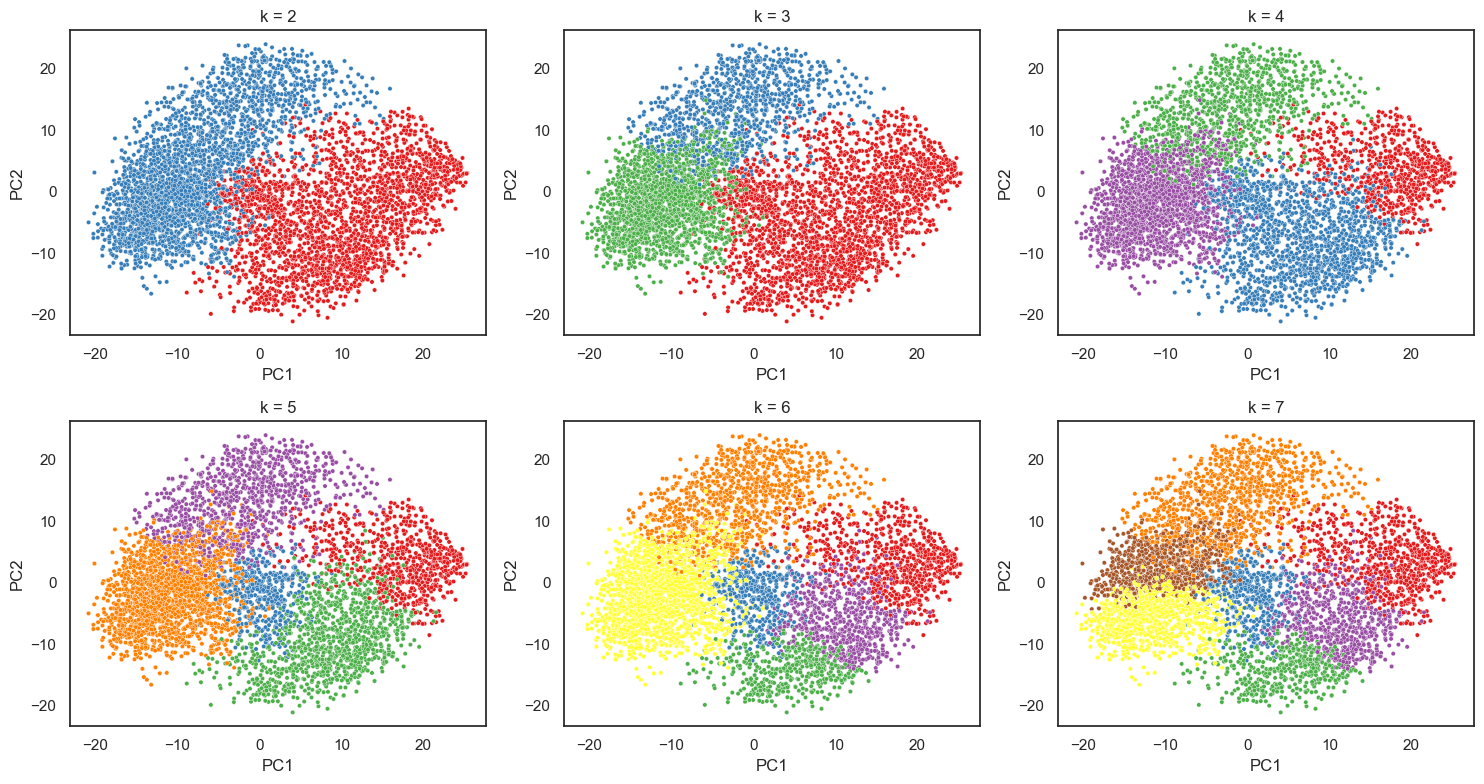

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # flatten to easily iterate over

# Loop over cluster numbers from 2 to 10
for i, k in enumerate(range(2, 8)):
    # Compute clusters using hierarchical clustering
    clusters = sch.fcluster(row_linkage1, k, criterion="maxclust")
    
    # Perform PCA on the cleaned data
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(proteins.values)
    
    # Create DataFrame for PCA results with cluster assignments
    pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=proteins.index)
    pca_df["Cluster"] = clusters
    
    # Plot on the corresponding axis
    ax = axes[i]
    sns.scatterplot(
        data=pca_df, 
        x="PC1", 
        y="PC2", 
        hue="Cluster", 
        palette="Set1", 
        s=10, 
        ax=ax,
        legend=False  # Disable legend for individual subplots
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

## PROTEIN EXPRESSION CLUSTERING 

In [2]:
protein_expr = load('data/proteomics_matched.joblib')
protein_expr = protein_expr.T

In [3]:
protein_expr

,MDAMB468_BREAST,SH4_SKIN,AU565_BREAST,KMRC1_KIDNEY,CAL51_BREAST,RPMI7951_SKIN,RERFLCMS_LUNG,IGR37_SKIN,VMRCRCW_KIDNEY,HEP3B217_LIVER,...,NCIH2030_LUNG,22RV1_PROSTATE,A172_CENTRAL_NERVOUS_SYSTEM,BT20_BREAST,CALU6_LUNG,FADU_UPPER_AERODIGESTIVE_TRACT,KP4_PANCREAS,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,OVCAR8_OVARY,THP1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
Gene_Symbol,,,,,,,,,,,,,,,,,,,,,
A2M,-0.345562,1.642186,-1.129114,1.493333,0.274652,-0.615667,-0.957249,-0.174494,-0.987932,1.513325,...,-0.981657,-0.921538,3.905544,-0.649348,-1.055916,-1.116991,1.922976,-1.106344,-0.770372,-1.342713
AAAS,-0.109405,-0.283335,0.024663,-0.588886,0.673324,0.010466,0.474615,0.037159,-0.362833,-0.225824,...,-0.093176,-0.518686,-0.642067,-0.188224,-0.259101,-0.779655,-0.628770,1.205109,-0.584588,1.622359
AACS,0.370945,0.162102,1.071283,0.404605,-0.587890,0.025699,-0.767258,-0.598630,0.219004,-0.319453,...,-0.887698,-0.488146,0.356932,0.936065,-0.876305,-0.343373,-1.200965,0.660346,-0.442688,0.662618
AAGAB,0.009639,-0.057517,-0.758048,-0.210457,-0.044001,0.381038,0.093162,0.303576,0.319783,-0.023510,...,0.756894,-1.125006,0.195036,1.314434,-0.362100,0.032533,2.101721,-0.539838,0.256127,-0.745283
AAK1,0.005800,0.760639,-0.320451,0.533949,-0.778679,0.333378,-0.111288,-0.267637,0.289226,-0.408265,...,0.154595,-0.627264,0.595116,1.415555,-0.291160,-1.433436,-0.549493,0.951283,-0.329806,0.751036
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.320284,-0.499179,-0.175592,-0.326172,-0.060968,-0.280411,0.248475,0.342934,0.050022,-0.175207,...,0.449259,-0.006234,-1.261002,-0.405626,-0.161832,0.125648,-0.052092,0.282679,0.905140,0.114861
ZW10,-0.109837,-0.208351,0.071945,0.019450,0.103745,0.055301,0.012701,0.110936,-0.075038,-0.322960,...,0.064839,-0.393597,0.091555,0.387981,-0.523405,-0.894195,-0.519440,0.672338,-0.647760,0.130053
ZWILCH,-0.234132,-0.163901,-0.393799,-0.055173,0.151656,0.167905,-0.304392,0.099581,0.193138,0.174065,...,-0.414665,-0.318647,-0.110500,0.110068,-0.274502,-0.610845,-0.873276,0.885732,-0.925121,0.431033


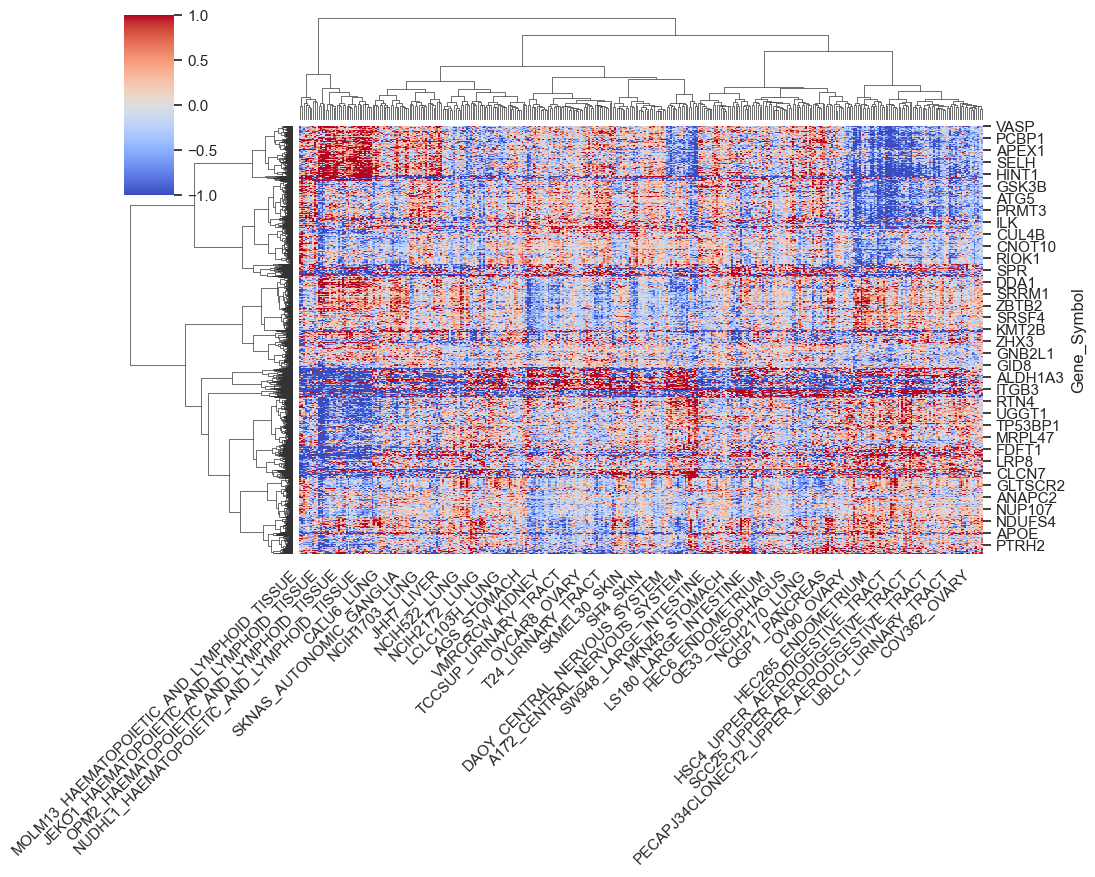

In [4]:

# Create directory if it doesn't exist
os.makedirs('results/clustermaps', exist_ok=True)

# Create the clustermap
sns.set_theme(style="white")
g = sns.clustermap(
    protein_expr,
    method="ward",         # Clustering method
    metric="euclidean",    # Distance metric
    cmap="coolwarm",       # Color map for correlation data
    center=0,              # Center the colormap at zero
    vmin=-1, vmax=1,       # Expected correlation range
    #standard_scale=1,      # Standardize each row (protein)
    figsize=(10, 10)       # Figure size
)

# Rotate x-axis labels for readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")

# Save the figure
g.savefig('results/clustermaps/map_pe_raw.png', dpi=300, bbox_inches='tight')

# Show the plot (optional - you can comment this out if running in a script)
plt.show()

standardized

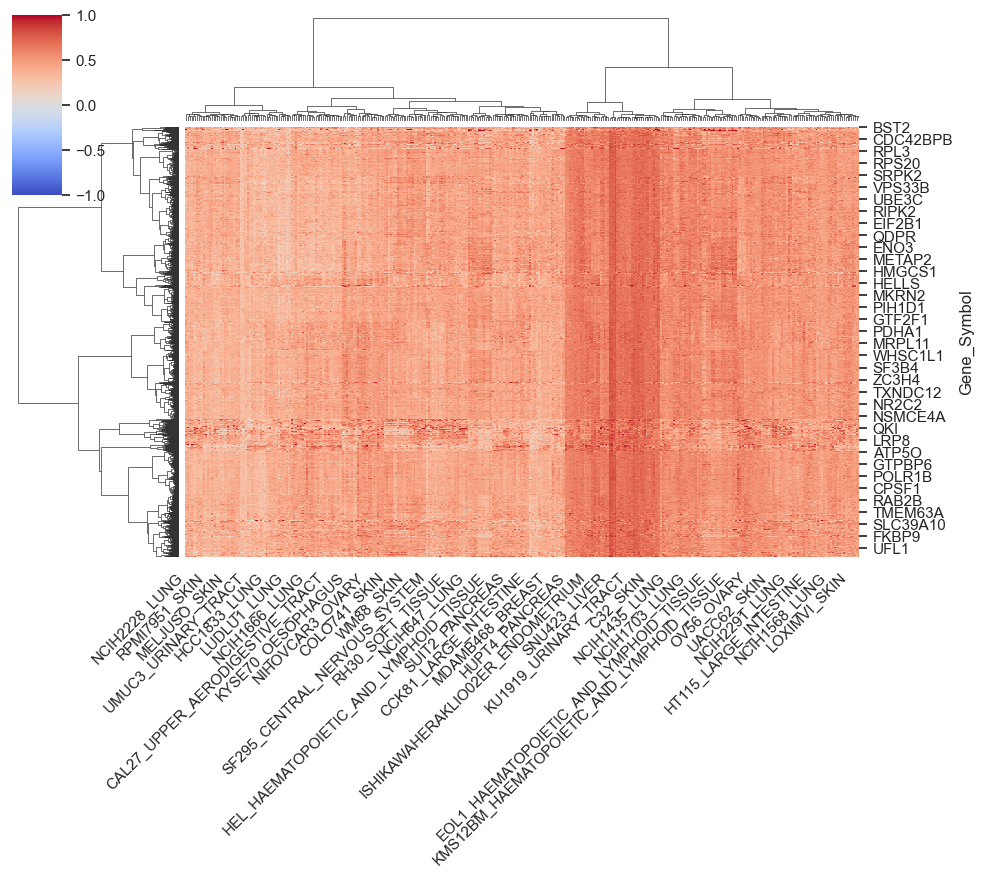

In [5]:
# Create the clustermap
sns.set_theme(style="white")
g = sns.clustermap(
    protein_expr,
    method="ward",         # Clustering method
    metric="euclidean",    # Distance metric
    cmap="coolwarm",       # Color map for correlation data
    center=0,              # Center the colormap at zero
    vmin=-1, vmax=1,       # Expected correlation range
    standard_scale=1,      # Standardize each row (protein)
    figsize=(10, 10)       # Figure size
)

# Rotate x-axis labels for readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")

# Save the figure
g.savefig('results/clustermaps/map_pe_std.png', dpi=300, bbox_inches='tight')

# Show the plot (optional - you can comment this out if running in a script)
plt.show()

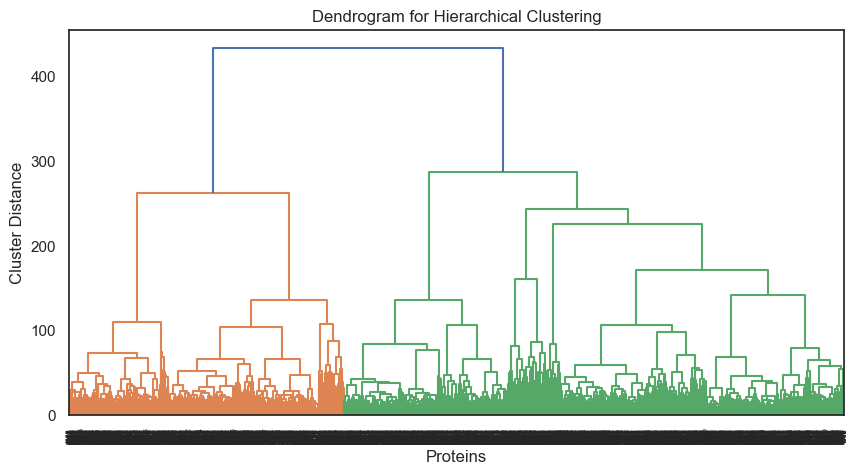

In [6]:
#row_linkage2 = g.dendrogram_row.linkage
row_linkage2 = sch.linkage(protein_expr, method="ward", metric="euclidean")

corr_utils.plot_dendrogram(row_linkage2)

#### Save clusters

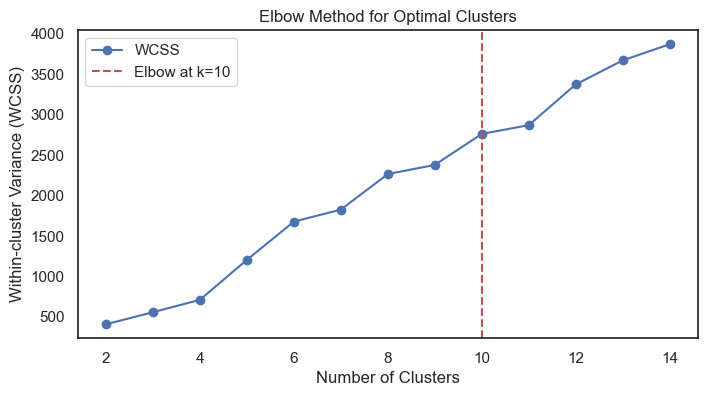

Saved cluster assignments for k=2 to 'results/clusters_pe/prot_expr_clusters_k2.csv'
Saved cluster assignments for k=3 to 'results/clusters_pe/prot_expr_clusters_k3.csv'
Saved cluster assignments for k=4 to 'results/clusters_pe/prot_expr_clusters_k4.csv'
Saved cluster assignments for k=5 to 'results/clusters_pe/prot_expr_clusters_k5.csv'
Saved cluster assignments for k=6 to 'results/clusters_pe/prot_expr_clusters_k6.csv'
Saved cluster assignments for k=7 to 'results/clusters_pe/prot_expr_clusters_k7.csv'

All cluster assignments from k=2 to k=2 have been saved to the 'results_pe' folder.


In [7]:
# 2. Elbow Method
elbow_k = corr_utils.elbow_method(protein_expr, row_linkage2)

# 3. Silhouette Score Method
silhouette_k = corr_utils.silhouette_method(protein_expr, row_linkage2)

# Extracting Cluster Assignments for multiple k values

# Create the directory if it doesn't exist
os.makedirs("results/clusters_pe", exist_ok=True)

# Save cluster assignments for all values from 2 to silhouette_k
for k in range(2, 8):
    # Get cluster labels for this k
    cluster_labels = fcluster(row_linkage2, k, criterion='maxclust')
    
    # Create a DataFrame mapping each protein to its cluster
    clusters_df = pd.DataFrame({
        'Protein': protein_expr.index,
        'Cluster': cluster_labels
    })
    
    # Define the output file path
    output_file = f"results/clusters_pe/prot_expr_clusters_k{k}.csv"
    
    # Save the cluster assignments to a CSV file
    clusters_df.to_csv(output_file, index=False)
    
    print(f"Saved cluster assignments for k={k} to '{output_file}'")

print(f"\nAll cluster assignments from k=2 to k={silhouette_k} have been saved to the 'results_pe' folder.")

PCA

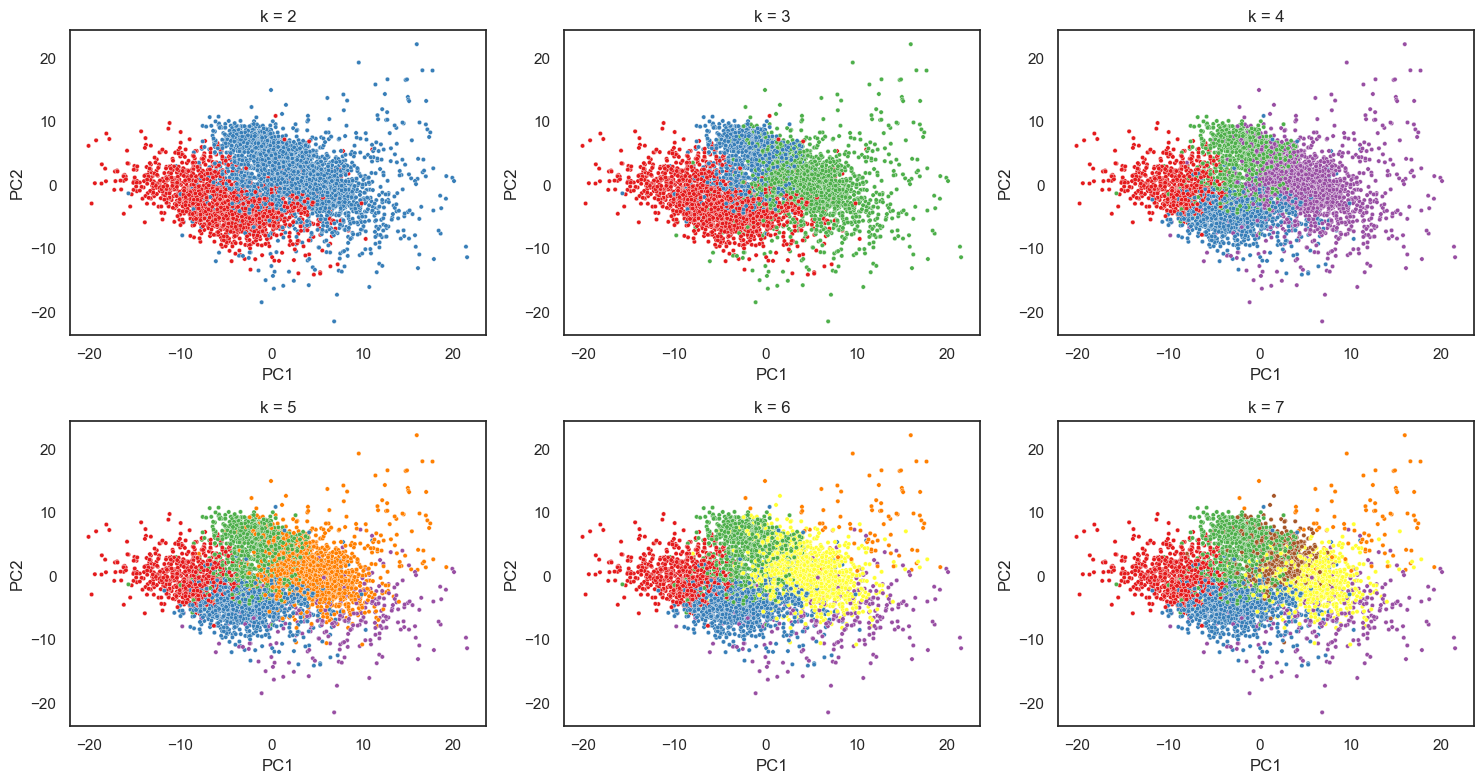

In [8]:

clusters = sch.fcluster(row_linkage2, 2, criterion="maxclust")
# Create a 2x5 grid for plots with a reduced overall figure size
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # flatten to easily iterate over
# Loop over cluster numbers from 2 to 10
for i, k in enumerate(range(2, 8)):
    # Compute clusters using hierarchical clustering
    clusters = sch.fcluster(row_linkage2, k, criterion="maxclust")
    
    # Perform PCA on the cleaned data
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(protein_expr.values)
    
    # Create DataFrame for PCA results with cluster assignments
    pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=protein_expr.index)
    pca_df["Cluster"] = clusters
    
    # Plot on the corresponding axis
    ax = axes[i]
    sns.scatterplot(
        data=pca_df, 
        x="PC1", 
        y="PC2", 
        hue="Cluster", 
        palette="Set1", 
        s=10, 
        ax=ax,
        legend=False  # Disable legend for individual subplots
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [9]:
clusters = sch.fcluster(row_linkage2, 3, criterion="maxclust")


Network Density: 0.0009954220837553299
Network Modularity: 0.7834906715419411

Top 5 Hub Proteins (by Degree Centrality):
PFDN6: 0.0278
SF3B2: 0.0264
UBE2N: 0.0256
UBE2NL: 0.0248
CIAPIN1: 0.0237


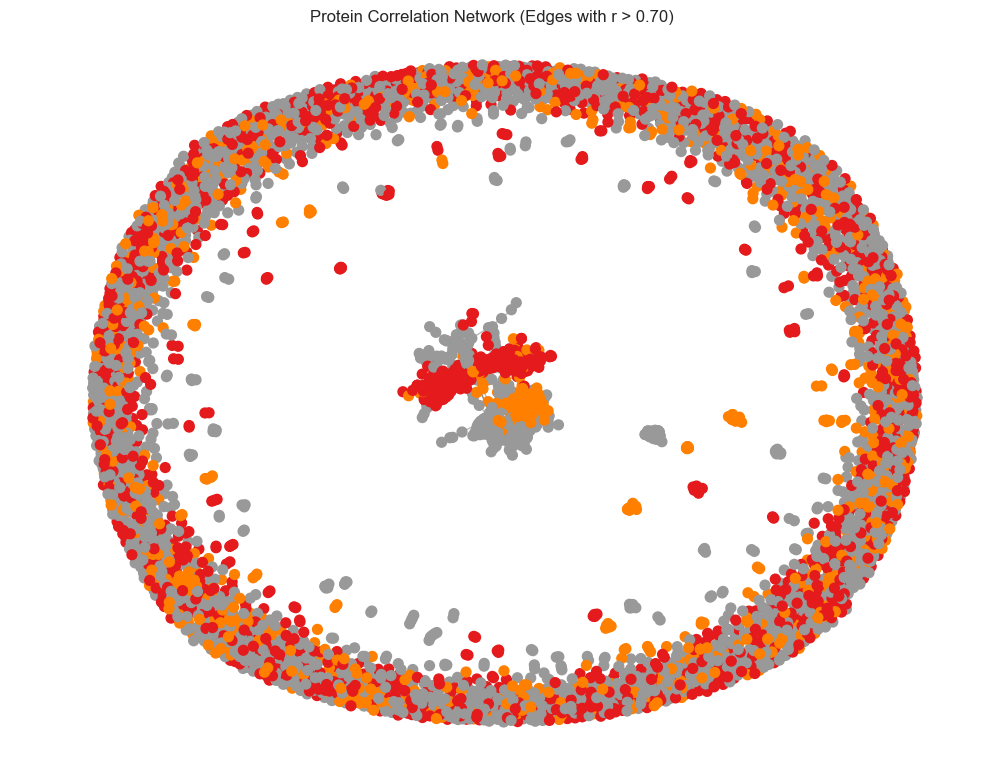

In [10]:
# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = protein_expr.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes 
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(protein_expr.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()

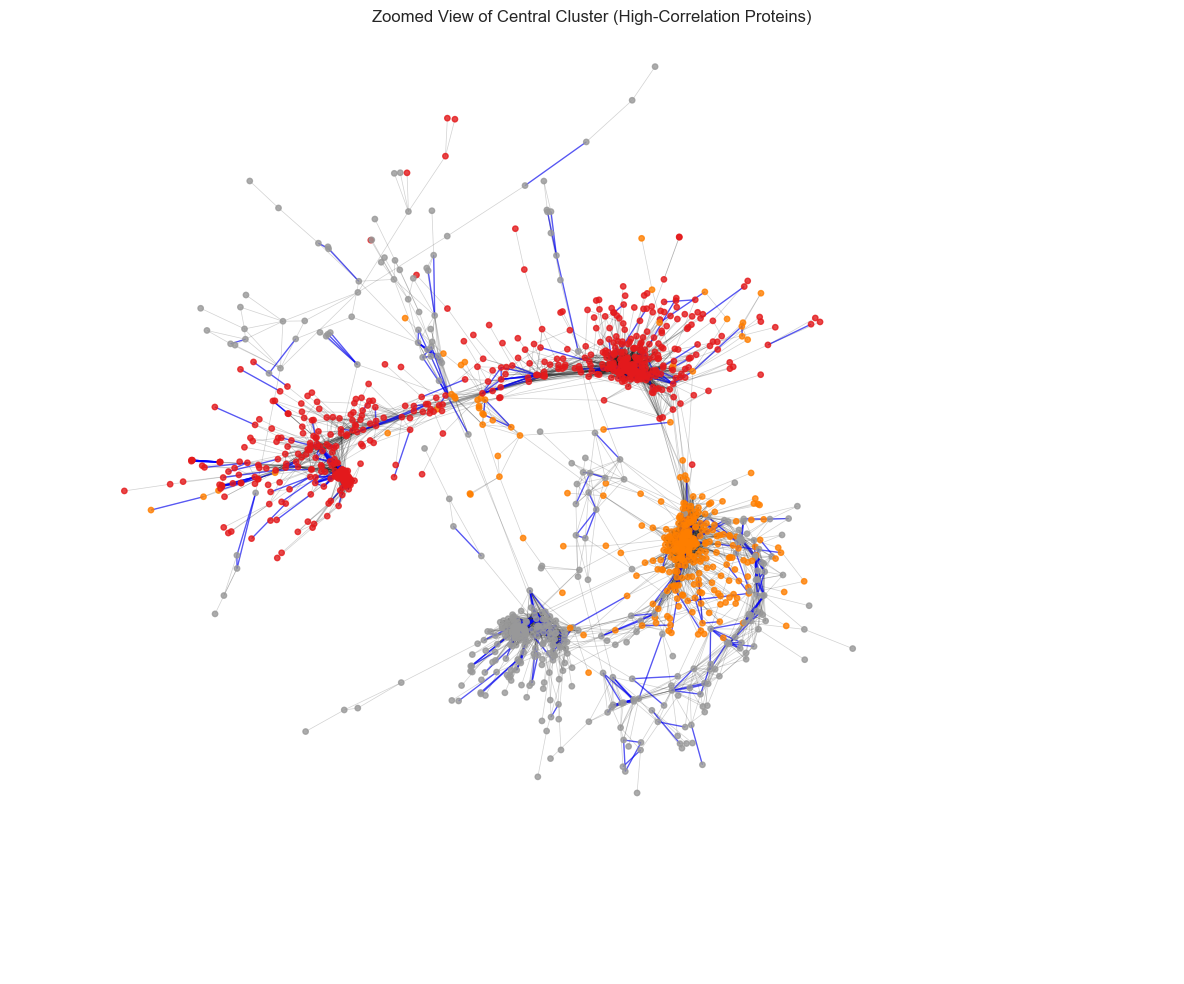

In [11]:
# Create zoomed version of central cluster
plt.figure(figsize=(12, 10))

# Get the same layout as the original visualization for consistency
pos = nx.spring_layout(G, seed=42)  # Use same seed as original for consistency

# Get the approximate center coordinates
x_coords = [coord[0] for coord in pos.values()]
y_coords = [coord[1] for coord in pos.values()]
center_x = sum(x_coords) / len(x_coords)
center_y = sum(y_coords) / len(y_coords)

# Define radius for central region
radius = 0.3  # Adjust this value to control zoom level

# Identify nodes in the central region
central_nodes = [node for node in G.nodes() if 
                ((pos[node][0] - center_x)**2 + (pos[node][1] - center_y)**2) < radius**2]

# Draw edges with increased transparency for better visibility
central_edge_list = [(u, v) for u, v in G.edges() if u in central_nodes and v in central_nodes]
central_G = nx.Graph()
central_G.add_edges_from(central_edge_list)
nx.draw_networkx_edges(central_G, pos, alpha=0.2, width=0.5)

# Draw high correlation edges more prominently
high_corr_edges = [(u, v) for u, v, d in G.edges(data=True) 
                  if d['weight'] > 0.8 and u in central_nodes and v in central_nodes]
high_corr_G = nx.Graph()
high_corr_G.add_edges_from(high_corr_edges)
nx.draw_networkx_edges(high_corr_G, pos, alpha=0.6, width=1.0, edge_color='blue')

# Draw nodes for central region
central_nodes_colors = [G.nodes[node]['cluster'] for node in central_nodes]
nx.draw_networkx_nodes(G, pos, nodelist=central_nodes, node_size=15, 
                      alpha=0.8, cmap=plt.cm.Set1, node_color=central_nodes_colors)

# Add labels for hub proteins in central region (top 10)
top_hubs = [protein for protein, _ in sorted_hubs[:10]]
#central_hub_labels = {node: node for node in top_hubs if node in central_nodes}
#nx.draw_networkx_labels(G, pos, labels=central_hub_labels, font_size=10, font_color='black', font_weight='bold')

# Set plot limits for zoom effect
plt.xlim(center_x - radius, center_x + radius)
plt.ylim(center_y - radius, center_y + radius)

plt.title("Zoomed View of Central Cluster (High-Correlation Proteins)")
plt.axis("off")
plt.tight_layout()
plt.savefig("zoomed_central_cluster.png", dpi=300)
plt.show()